# Data Mining — Linear Regression — Mini-Project 1 (Energy Consumption)

**Course:** [CSEN911] Data Mining (Winter 2025)  
**Instructor:** Dr. Ayman Alserafi  
**Due:** 24 October 2025, 11:59 PM

**Dataset:** `energy_data.csv`  


> **Instructions:** For every step, write your own explanations and justifications and visualization in the provided Markdown prompts.




***Edit this cell with your name(s), tutorial number(s) and ID(s)***

---

Name: Mohamed Amir

ID: 58-0518

Tutorial: T12

---

Name:

ID:

Tutorial:

---


The dataset contains building-level energy readings and contextual attributes.

Each row represents a building observation. Columns include:

<div style="font-size:20px;">

| **Column** | **Description** |
|-------------|-----------------|
| **Building_ID** | Unique identifier for each building record. Used to distinguish one building entry from another. |
| **Building_Type** | Category describing the primary use of the building (e.g., Residential, Commercial, Industrial, Educational, etc.). |
| **Governorate** | The administrative region (governorate) where the building is located (e.g., Cairo, Giza, Alexandria). |
| **Neighborhood** | The smaller district or local area within the governorate where the building is located. |
| **Day_of_Week** | The day on which the energy consumption measurement was recorded (e.g., Sunday, Monday, etc.). |
| **Occupancy_Level** | The relative number of occupants or activity level in the building, typically categorized as *Low*, *Medium*, or *High*. |
| **Appliances_Usage_Level** | Indicates how intensively appliances are used in the building *Low*, *Medium*, or *High*. |
| **SquareFootage** | The total floor area of the building (numeric). Serves as a proxy for building size, often influencing energy usage. |
| **Last_Maintenance_Date** | The date of the last maintainance done on the building. |
| **Average_Temperature** | The average ambient temperature (in °C) recorded during the data period. |
| **Energy_Consumption** | The total energy used by the building, typically measured in kilowatt-hours (kWh).|

</div>


## Importing Libraries & Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    df = pd.read_csv('energy_data.csv')
except:
    df = pd.read_csv('https://raw.githubusercontent.com/GUC-DM/W2025/refs/heads/main/data/energy_data.csv')

df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption
0,BLD-1000-UD,Residential,Alexandria,Smouha,WeDnesday,High,Low,7063m2,2020-01-01,28.61,2713.95 kWh
1,BLD-1001-AX,Commercial,Giza,+Mohandessin14,tuesDAY,High,High,44372m2,2022-02-24,NaN,5744.99 kWh
2,BLD-1002-IH,Industrial,Cairo,New Cairo,SunDay,Medium,Low,19255,2021-02-22,37.88,4101.24 kWh
3,BLD-1003-HE,NaN,NaN,+92Dokki,TuesDay,Low,High,13265,2023-07-30,35.06,3009.14 kWh
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17 kWh


## Data Inspection

Perform data inspection tasks here (recommended for data understanding).

In [2]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))

print("\n--- dtypes & non-null counts ---")
display(df.dtypes)

print("\nInfo():")
print(df.info())

print("\n--- Null counts ---")
display(df.isna().sum().sort_values(ascending=False).to_frame("null_count"))

print("\n--- Numeric summary ---")
display(df.select_dtypes(include="number").describe().T)

obj_cols = df.select_dtypes(include="object").columns.tolist()
print("\n--- Categorical columns & unique counts ---")
display(pd.Series({c: df[c].nunique(dropna=True) for c in obj_cols}).sort_values(ascending=False).to_frame("n_unique"))

display(df.head(5))

Shape: (1100, 11)

Columns: ['Building_ID', 'Building_Type', 'Governorate', 'Neighborhood', 'Day_of_Week', 'Occupancy_Level', 'Appliances_Usage_Level', 'SquareFootage', 'Last_Maintenance_Date', 'Average_Temperature', 'Energy_Consumption']

--- dtypes & non-null counts ---


,0
Building_ID,object
Building_Type,object
Governorate,object
Neighborhood,object
Day_of_Week,object
Occupancy_Level,object
Appliances_Usage_Level,object
SquareFootage,object
Last_Maintenance_Date,object
Average_Temperature,float64



Info():
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Building_ID             1100 non-null   object 
 1   Building_Type           990 non-null    object 
 2   Governorate             873 non-null    object 
 3   Neighborhood            1100 non-null   object 
 4   Day_of_Week             1100 non-null   object 
 5   Occupancy_Level         1100 non-null   object 
 6   Appliances_Usage_Level  1100 non-null   object 
 7   SquareFootage           1100 non-null   object 
 8   Last_Maintenance_Date   1100 non-null   object 
 9   Average_Temperature     990 non-null    float64
 10  Energy_Consumption      1100 non-null   object 
dtypes: float64(1), object(10)
memory usage: 94.7+ KB
None

--- Null counts ---


,null_count
Governorate,227
Building_Type,110
Average_Temperature,110
Building_ID,0
Neighborhood,0
Occupancy_Level,0
Day_of_Week,0
Appliances_Usage_Level,0
SquareFootage,0
Last_Maintenance_Date,0



--- Numeric summary ---


,count,mean,std,min,25%,50%,75%,max
Average_Temperature,990.0,33.499404,10.703806,-4.91,29.4225,35.26,39.97,50.0



--- Categorical columns & unique counts ---


,n_unique
Building_ID,1100
Energy_Consumption,1100
SquareFootage,1095
Neighborhood,848
Last_Maintenance_Date,727
Day_of_Week,42
Building_Type,3
Governorate,3
Occupancy_Level,3
Appliances_Usage_Level,3


,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption
0,BLD-1000-UD,Residential,Alexandria,Smouha,WeDnesday,High,Low,7063m2,2020-01-01,28.61,2713.95 kWh
1,BLD-1001-AX,Commercial,Giza,+Mohandessin14,tuesDAY,High,High,44372m2,2022-02-24,NaN,5744.99 kWh
2,BLD-1002-IH,Industrial,Cairo,New Cairo,SunDay,Medium,Low,19255,2021-02-22,37.88,4101.24 kWh
3,BLD-1003-HE,NaN,NaN,+92Dokki,TuesDay,Low,High,13265,2023-07-30,35.06,3009.14 kWh
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17 kWh


## Data Pre-Processing & Cleaning

_Apply any data preprocessing and/or feature engineering below. Show/output the changes to the dataset._

In [14]:
df_clean = df.copy()

for c in df_clean.select_dtypes(include="object").columns:
    df_clean[c] = df_clean[c].astype(str).str.strip()

for c in ["Building_Type", "Neighborhood", "Governorate"]:
    if c in df_clean.columns:
        df_clean[c] = df_clean[c].str.lower()

if "Energy_Consumption" in df_clean.columns:
    df_clean["Energy_Consumption"] = (
        df_clean["Energy_Consumption"].astype(str)
        .str.replace(r"[^\d\.\-]", "", regex=True)
        .replace({"": np.nan})
        .astype(float)
    )

if "SquareFootage" in df_clean.columns:
    df_clean["SquareFootage"] = (
        df_clean["SquareFootage"].astype(str)
        .str.replace(r"[^\d\.\-]", "", regex=True)
        .replace({"": np.nan})
        .astype(float)
    )

if "Average_Temperature" in df_clean.columns and df_clean["Average_Temperature"].dtype == "object":
    df_clean["Average_Temperature"] = pd.to_numeric(df_clean["Average_Temperature"], errors="coerce")

rename_map = {
    "Energy_Consumption": "energy_consumption",
    "SquareFootage": "building_size",
    "Average_Temperature": "avg_temperature",
    "Last_Maintenance_Date": "last_maintenance_date",
    "Day_of_Week": "day_of_week",
    "Neighborhood": "neighborhood",
    "Governorate": "governorate",
    "Building_Type": "building_type"
}
existing = {k: v for k, v in rename_map.items() if k in df_clean.columns}
df_clean = df_clean.rename(columns=existing)

likely_numeric = ["energy_consumption", "building_size", "avg_temperature", "num_occupants"]
for c in likely_numeric:
    if c in df_clean.columns and df_clean[c].dtype == "object":
        df_clean[c] = pd.to_numeric(df_clean[c], errors="coerce")

date_cols = {
    "date": ["date", "reading_date", "timestamp"],
    "last_maintenance_date": ["last_maintenance_date", "maintenance_date"]
}
for canonical, candidates in date_cols.items():
    for cand in candidates:
        if cand in df_clean.columns:
            df_clean[canonical] = pd.to_datetime(df_clean[cand], errors="coerce")
            break

num_cols = df_clean.select_dtypes(include="number").columns.tolist()
cat_cols = df_clean.select_dtypes(exclude="number").columns.tolist()
before_nulls = df_clean.isna().sum()

for c in num_cols:
    if df_clean[c].isna().any():
        df_clean[c] = df_clean[c].fillna(df_clean[c].median())

for c in cat_cols:
    if df_clean[c].isna().any():
        mode_val = df_clean[c].mode(dropna=True)
        fill_val = mode_val.iloc[0] if not mode_val.empty else "unknown"
        df_clean[c] = df_clean[c].fillna(fill_val)

after_nulls = df_clean.isna().sum()

print("Nulls before → after (top 15):")
display(pd.concat([before_nulls, after_nulls], axis=1, keys=["before", "after"]).sort_values("before", ascending=False).head(15))
display(df_clean.head(5))


Nulls before → after (top 15):


,before,after
avg_temperature,110,0
building_type,0,0
Building_ID,0,0
governorate,0,0
neighborhood,0,0
Occupancy_Level,0,0
day_of_week,0,0
Appliances_Usage_Level,0,0
building_size,0,0
last_maintenance_date,0,0


,Building_ID,building_type,governorate,neighborhood,day_of_week,Occupancy_Level,Appliances_Usage_Level,building_size,last_maintenance_date,avg_temperature,energy_consumption
0,BLD-1000-UD,residential,alexandria,smouha,WeDnesday,High,Low,70632.0,2020-01-01,28.61,2713.95
1,BLD-1001-AX,commercial,giza,+mohandessin14,tuesDAY,High,High,443722.0,2022-02-24,35.26,5744.99
2,BLD-1002-IH,industrial,cairo,new cairo,SunDay,Medium,Low,19255.0,2021-02-22,37.88,4101.24
3,BLD-1003-HE,nan,nan,+92dokki,TuesDay,Low,High,13265.0,2023-07-30,35.06,3009.14
4,BLD-1004-XD,commercial,alexandria,smouha,Monday,Low,Low,13375.0,2022-08-12,28.82,3279.17


## Feature Engineering

## Exploratory Data Analysis

**Q1:** What are the most popular neighborhoods? plot all and order them on the graph (mention top 3)

**Visualization**

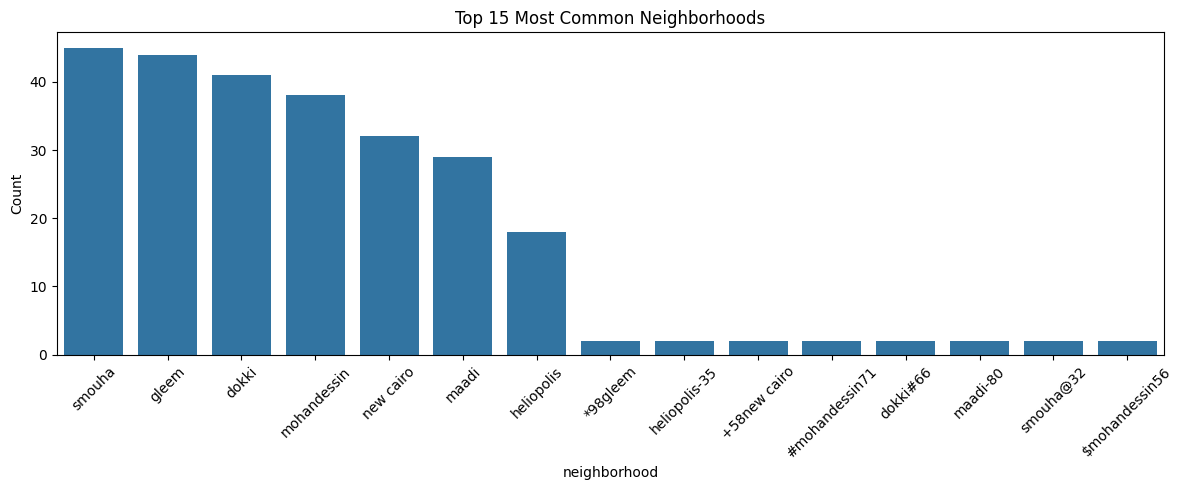

Top 3 Neighborhoods:


,count
neighborhood,
smouha,45
gleem,44
dokki,41


In [19]:
# Q1: Most popular neighborhoods
nb_col = "neighborhood" if "neighborhood" in df_clean.columns else (
         "Neighborhood" if "Neighborhood" in df_clean.columns else None)

if nb_col:
    nb_counts = df_clean[nb_col].value_counts()
    top15 = nb_counts.head(15)

    plt.figure(figsize=(12,5))
    sns.barplot(x=top15.index, y=top15.values)
    plt.title("Top 15 Most Common Neighborhoods")
    plt.xlabel(nb_col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print("Top 3 Neighborhoods:")
    display(nb_counts.head(3).to_frame("count"))
else:
    print("No neighborhood-like column found.")


**Answer for Q1:** _Your answer here_

1.   Smouha
2.   Gleem
3.   Dokki

the graph here displays only the top 15 as displaying all neighborhoods resulted in a messy and a not understandable graph



**Q2:** Show the distribution of the energy consumption of each Building type.

Which type have the widest distribution of energy consumption?

Which (on average) has the highest consumption?.

**Visualization**

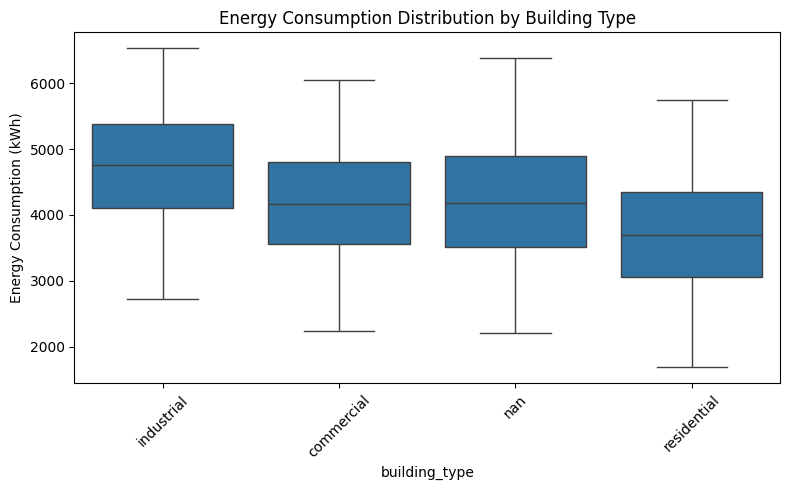

,count,mean,std,min,max
building_type,,,,,
industrial,316,4708.418671,818.158005,2724.82,6530.60
commercial,325,4170.374462,809.695114,2241.96,6042.56
nan,110,4160.626091,949.703360,2205.20,6383.50
residential,349,3679.396934,833.337177,1683.95,5746.40


In [21]:
bt_col = "building_type" if "building_type" in df_clean.columns else (
         "Building_Type" if "Building_Type" in df_clean.columns else None)
target = "energy_consumption" if "energy_consumption" in df_clean.columns else (
         "Energy_Consumption" if "Energy_Consumption" in df_clean.columns else None)

if bt_col and target:
    if df_clean[target].dtype == "object":
        tmp = (
            df_clean[target].astype(str)
            .str.replace(r"[^\d\.\-]", "", regex=True)
            .replace({"": np.nan})
            .astype(float)
        )
        df_clean[target] = tmp

    data = df_clean[[bt_col, target]].dropna()

    plt.figure(figsize=(8,5))
    order = data.groupby(bt_col)[target].mean().sort_values(ascending=False).index
    sns.boxplot(data=data, x=bt_col, y=target, order=order)
    plt.title("Energy Consumption Distribution by Building Type")
    plt.xlabel(bt_col); plt.ylabel("Energy Consumption (kWh)")
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

    stats = data.groupby(bt_col)[target].agg(["count","mean","std","min","max"]).sort_values("mean", ascending=False)
    display(stats)
else:
    print("building_type / energy_consumption not found (run cleaning cell first).")

**Answer for Q2:**  the highest spread is in the residential buildings as they have the highest difference between min and max and the highest average is the Industrial.

**Q3:** How does the building size affect energy consumption?

**Visualization**

**Answer for Q3:** _Your answer here_

**Q4:** Do buildings consume more energy if not maintained frequently?

**Visualization**

**Answer for Q4:** _Your answer here_

**Q5:** Are all the numerical variables normally distributed, or is there any skewness?

**Visualization**

**Answer for Q5:** _Your answer here_

**Q6:** What is multicollinearity? And why is it a problem for linear regression? Does this problem exist in this
dataset?

**Visualization**

**Answer for Q6:** _Your answer here_

## Data Preparation for Modelling

_Apply any additional data preparation steps needed before modelling below. Show/output the changes to the dataset._

## Modelling

_Apply the linear regression model below._

## Model Evaluation

Evaluate the model you applied.

## Conclusion and Recommendations

Comment on the model performance and your findings from model evaluation. State the problems (if any) and suggest possible solutions. Would you recommend this model for an electrcity company aiming to estimate the energy levels of each building?

**Answer**: your answer here.